# Actionable-CBFI: Comprehensive Tutorial & User Guide
### *Bridging Structural Causal Decomposition and Actionable Counterfactual Recourse*

Welcome to the beginner-friendly tutorial for **Actionable-CBFI (A-CBFI)**!

In machine learning applications where decisions have high-stakes consequences—such as loan underwriting, medical diagnosis, and hiring—standard Explainable AI (XAI) methods (like SHAP and LIME) explain **what features correlated with the outcome**, but they fail to answer:
1. **Can the user actually change this feature?** (Actionable vs. Immutable features like Age or Race).
2. **What happens to related features when an action is taken?** (Causal ripple effects via Structural Causal Models).
3. **Do features act independently or synergistically?** (Interaction bottlenecks and interference).

**Actionable-CBFI** solves these challenges by combining **Causal Bottleneck Feature Importance (CBFI)** with **Actionable Counterfactual Recourse** across three hierarchical levels:

* **Level 1 (Node Diagnosis)**: Decomposes each variable's influence into its **Causal Main Effect ($C_{G1}$)** and **Causal Interaction Effect ($C_{G4}$)** while filtering out immutable constraints.
* **Level 2 (Interaction Diagnosis)**: Quantifies the signed pairwise interaction matrix $C_{G4}(X_i, X_j)$ to discover cooperative synergies or destructive interferences among features.
* **Level 3 (Causal Search & Recourse)**: Uses an interaction-guided beam search over a **Structural Causal Model (SCM)** to prescribe the minimum-cost, causally plausible intervention that flips an adverse prediction to the desired outcome.

---

## Table of Contents
1. [Environment Setup & Imports](#1.-Environment-Setup-&-Imports)
2. [Building the Structural Causal Model (SCM)](#2.-Building-the-Structural-Causal-Model-(SCM))
3. [Synthetic Credit/Loan Dataset & Model Training](#3.-Synthetic-Credit/Loan-Dataset-&-Model-Training)
4. [Selecting an Adverse Factual Applicant](#4.-Selecting-an-Adverse-Factual-Applicant)
5. [Level 1: Node Diagnosis ($C_{G1}$ & $C_{G4}$)](#5.-Level-1:-Node-Diagnosis-(C_{G1}-&-C_{G4}))
6. [Level 1 Visualizations: Waterfall & Decomposition Plots](#6.-Level-1-Visualizations:-Waterfall-&-Decomposition-Plots)
7. [Level 2: Interaction Diagnosis (Pairwise Synergy Matrix)](#7.-Level-2:-Interaction-Diagnosis-(Pairwise-Synergy-Matrix))
8. [Level 2 Visualizations: Diagnosis Matrix Heatmap & Interaction Graph $\mathcal{G}_I$](#8.-Level-2-Visualizations:-Diagnosis-Matrix-Heatmap-&-Interaction-Graph-\mathcal{G}_I)
9. [Level 3: Prescribing Actionable Counterfactual Recourse](#9.-Level-3:-Prescribing-Actionable-Counterfactual-Recourse)
10. [Level 3 Visualizations: Recourse Waterfall & Causal DAG Propagation](#10.-Level-3-Visualizations:-Recourse-Waterfall-&-Causal-DAG-Propagation)
11. [Evaluating Recourse Quality: Sparsity & Causal Plausibility](#11.-Evaluating-Recourse-Quality:-Sparsity-&-Causal-Plausibility)
12. [All-in-One High-Level Interface: `ActionableCBFI`](#12.-All-in-One-High-Level-Interface:-ActionableCBFI)
13. [Summary & Best Practices](#13.-Summary-&-Best-Practices)


---
## 1. Environment Setup & Imports

Let's begin by importing required libraries (`numpy`, `pandas`, `sklearn`, `matplotlib`, `networkx`) along with the two core modules:
- `Actionable_CBFI`: Defines the SCM, the Diagnoser, the Solver, and evaluation metrics.
- `Visualize_CBFI` (or `Visualize_ACBFI`): Publication-quality plotting tools tailored for causal diagnosis and recourse.


In [1]:
# Enable inline plotting in Jupyter Notebook
%matplotlib inline

import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.ensemble import RandomForestClassifier

# Import core classes and functions from Actionable_CBFI
from Actionable_CBFI import (
    StructuralCausalModel,
    CausalCBFIDiagnoser,
    ActionableCBFISolver,
    ActionableCBFI,
    compute_search_efficiency,
    compute_sparsity,
    compute_causal_plausibility
)

# Import specialized visualization functions from Visualize_CBFI
import Visualize_CBFI as vis

print("Actionable-CBFI and visualization modules imported successfully!")


Actionable-CBFI and visualization modules imported successfully!


---
## 2. Building the Structural Causal Model (SCM)

A **Structural Causal Model (SCM)** represents the true underlying data-generating mechanism using:
1. A **Directed Acyclic Graph (DAG)**: $\mathcal{G} = (\mathcal{V}, \mathcal{E})$, where an edge $A 
ightarrow B$ means variable $A$ causally influences variable $B$.
2. **Structural Equations**: For each child node $B$, a mathematical function $f_B(	ext{Parents}(B), U_B)$ determines its value based on its causal parents and independent background noise $U_B$.

### Domain Example: Loan Underwriting & Credit Risk
Consider a financial domain with 6 features:
- `Age`: Biological age (**Immutable**).
- `Income`: Annual income (**Actionable**).
- `Tenure`: Employment history in years (**Actionable**).
- `Debt`: Outstanding debt (**Actionable**).
- `Savings`: Cash savings balance (**Downstream** of Income & Debt).
- `CreditScore`: Creditworthiness index (**Downstream** of Income, Debt, & Tenure).

Let's see how easy it is to define and inspect this causal DAG with `StructuralCausalModel`.


In [2]:
# Define DAG edges (Parent -> Child)
dag_edges = [
    ('Income', 'Savings'),
    ('Debt', 'Savings'),
    ('Income', 'CreditScore'),
    ('Debt', 'CreditScore'),
    ('Tenure', 'CreditScore')
]

feature_nodes = ['Age', 'Income', 'Tenure', 'Debt', 'Savings', 'CreditScore']

# Initialize the SCM
scm = StructuralCausalModel(dag_edges=dag_edges, nodes=feature_nodes)

print("SCM Topological Order:", scm._topological_order)
print("Parents of Savings:", scm.get_parents('Savings'))
print("Parents of CreditScore:", scm.get_parents('CreditScore'))
print("Descendants of Income:", scm.get_descendants('Income'))


SCM Topological Order: ['Age', 'Income', 'Tenure', 'Debt', 'Savings', 'CreditScore']
Parents of Savings: ['Income', 'Debt']
Parents of CreditScore: ['Income', 'Debt', 'Tenure']
Descendants of Income: ['CreditScore', 'Savings']


---
## 3. Synthetic Credit/Loan Dataset & Model Training

To demonstrate how the SCM interacts with machine learning, let's generate a realistic synthetic dataset where:
- `Savings` is causally generated from `Income` and `Debt`.
- `CreditScore` is causally determined by `Income`, `Debt`, and `Tenure`.
- A black-box classifier (`RandomForestClassifier`) predicts **Loan Denial ($Y=1$)** vs. **Approval ($Y=0$)**.


In [3]:
np.random.seed(42)
N = 1000

# Exogenous (root) variables
age = np.random.uniform(22, 65, N)
income = np.random.uniform(25000, 120000, N)
tenure = np.random.uniform(1, 15, N)
debt = np.random.uniform(2000, 40000, N)

# Endogenous (causally generated) variables according to structural equations
noise_savings = np.random.normal(0, 1000, N)
savings = 0.35 * income - 0.10 * debt + noise_savings

noise_credit = np.random.normal(0, 15, N)
credit_score = 500.0 + 0.0020 * income - 0.0075 * debt + 10.0 * tenure + noise_credit

# Assemble DataFrame
df = pd.DataFrame({
    'Age': np.round(age, 1),
    'Income': np.round(income, 2),
    'Tenure': np.round(tenure, 1),
    'Debt': np.round(debt, 2),
    'Savings': np.round(savings, 2),
    'CreditScore': np.round(credit_score, 1)
})

# Ground truth probability of Loan Denial (Class 1) based on low credit score
denial_logit = (570.0 - credit_score) / 25.0
denial_prob = 1.0 / (1.0 + np.exp(-denial_logit))
y = (denial_prob > 0.5).astype(int)

print(f"Dataset Shape: {df.shape}")
print(f"Class Distribution: {np.bincount(y)} (0: Approved, 1: Denied)")
display(df.head())


Dataset Shape: (1000, 6)
Class Distribution: [491 509] (0: Approved, 1: Denied)


,Age,Income,Tenure,Debt,Savings,CreditScore
0,38.1,42587.63,4.7,27562.71,13478.04,415.3
1,62.9,76480.59,4.5,32273.89,23854.00,456.7
2,53.5,107929.85,13.7,11517.78,36017.17,766.5
3,47.7,94561.36,4.5,25745.22,30977.86,548.2
4,28.7,101623.31,4.8,23726.35,32736.43,569.3


### Fitting Structural Equations into the SCM
`StructuralCausalModel.fit_from_data(df, dag_edges)` automatically fits regressions (e.g. `LinearRegression` or custom regressors) for each child node based on its parents. This allows the SCM to perform **causal do-interventions**: $do(X_i = v)$.


In [4]:
# Fit SCM parameters from data
scm.fit_from_data(df, dag_edges=dag_edges)

# Train our predictive model (Random Forest Classifier)
clf = RandomForestClassifier(n_estimators=50, random_state=42)
clf.fit(df, y)

train_acc = clf.score(df, y)
print(f"Random Forest Classifier trained successfully! Training Accuracy: {train_acc * 100:.2f}%")


Random Forest Classifier trained successfully! Training Accuracy: 100.00%


---
## 4. Selecting an Adverse Factual Applicant

Now let's pick an applicant whose loan was **DENIED** ($Y=1$, High Risk), but who wants an explanation and an **actionable recourse plan** to achieve **Approval** ($Y=0$).


In [5]:
# Pick a specific applicant with high debt, low tenure, and poor credit score
factual_applicant = pd.Series({
    'Age': 46.0,
    'Income': 34000.0,
    'Tenure': 2.0,
    'Debt': 29000.0,
    'Savings': 3500.0,
    'CreditScore': 455.0
})

pred_class = clf.predict(pd.DataFrame([factual_applicant]))[0]
pred_prob = clf.predict_proba(pd.DataFrame([factual_applicant]))[0, 1]

print("=== FACTUAL APPLICANT PROFILE ===")
for k, v in factual_applicant.items():
    print(f"{k:>12}: {v}")
print("-" * 35)
print(f"Model Prediction : {'Loan DENIED (Class 1)' if pred_class == 1 else 'Loan APPROVED (Class 0)'}")
print(f"Denial Probability: {pred_prob * 100:.2f}%")


=== FACTUAL APPLICANT PROFILE ===
         Age: 46.0
      Income: 34000.0
      Tenure: 2.0
        Debt: 29000.0
     Savings: 3500.0
 CreditScore: 455.0
-----------------------------------
Model Prediction : Loan DENIED (Class 1)
Denial Probability: 100.00%


---
## 5. Level 1: Node Diagnosis ($C_{G1}$ & $C_{G4}$)

Standard feature importance treats all features as isolated and mutable. In contrast, **`CausalCBFIDiagnoser`**:
1. **Separates Actionable vs. Immutable Variables**: Protects immutable variables (like `Age`) from being targeted for intervention.
2. **C-G1 (Causal Main Effect)**: Measures the expected prediction shift when intervening solely on $X_i$ via $do(X_i = v)$, propagating changes through the SCM.
3. **C-G4 (Node Interaction Effect)**: Measures whether $X_i$ acts synergistically with or causes interference against other variables.
4. **Total Causal Importance**: $|C_{G1}| + |C_{G4}|$.
5. **Target Candidate Selection ($T$)**: Identifies the critical subset of actionable bottleneck features that should be considered for counterfactual search.


In [6]:
# Initialize Level 1 Diagnoser with SCM
diagnoser = CausalCBFIDiagnoser(scm)

# Perform Node-Level Diagnosis
df_diag, target_nodes = diagnoser.diagnose_instance(
    model=clf,
    instance=factual_applicant,
    background_data=df,
    job_type='classification',
    immutable_features=['Age'],  # Age cannot be altered!
    n_samples=50,
    use_proba=True
)

print(f"Diagnosed Target Candidate Nodes (T): {target_nodes}\n")
display(df_diag)


Diagnosed Target Candidate Nodes (T): ['Income', 'Debt', 'CreditScore', 'Tenure']



,C-G1 (Main Effect),C-G4 (Interaction),Total Causal Importance,Actionable
Feature,,,,
Income,0.3324,0.113333,0.445733,True
Debt,0.2860,0.065600,0.351600,True
CreditScore,0.3292,0.006533,0.335733,True
Tenure,0.0484,0.121333,0.169733,True
Savings,0.0180,0.000800,0.018800,True
Age,0.0000,0.000267,0.000267,False


---
## 6. Level 1 Visualizations: Waterfall & Decomposition Plots

The `Visualize_CBFI` module provides two key plots for Level 1:

### 1) `plot_base_diagnosis_waterfall` (SHAP-Style Causal Risk Waterfall)
Renders a horizontal waterfall chart starting from the baseline population risk $E[f(X)]$ and shows how each feature value contributed to increasing (+ risk) or decreasing (- protective) the applicant's denial probability, broken down into $C_{G1}$ (Main Effect) and $C_{G4}$ (Interaction Effect).


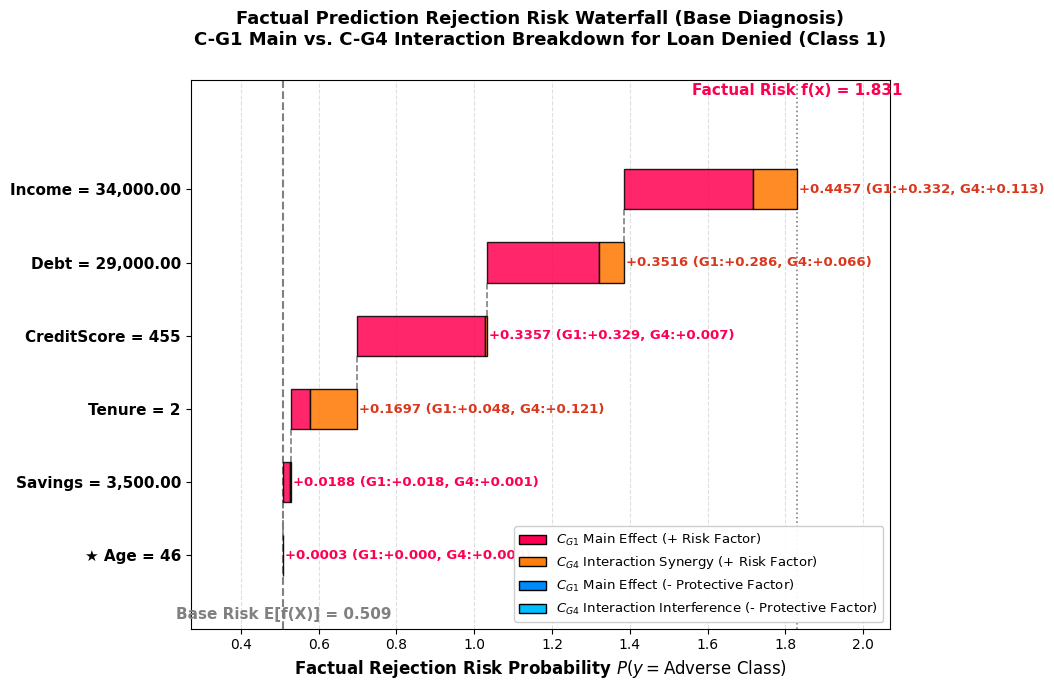

In [7]:
fig_waterfall = vis.plot_base_diagnosis_waterfall(
    df_diag=df_diag,
    instance=factual_applicant,
    model=clf,
    background_data=df,
    prediction_label="Loan Denied (Class 1)",
    immutable_features=['Age'],
    show_plot=True
)


### 2) `plot_main_interaction_decomposition` (Stacked Main/Interaction Bar Chart)
Visualizes how each feature's total causal importance splits between **C-G1 (Main Effect, Blue)** and **C-G4 (Interaction Effect, Orange)**. Features prefixed with $\star$ are immutable.


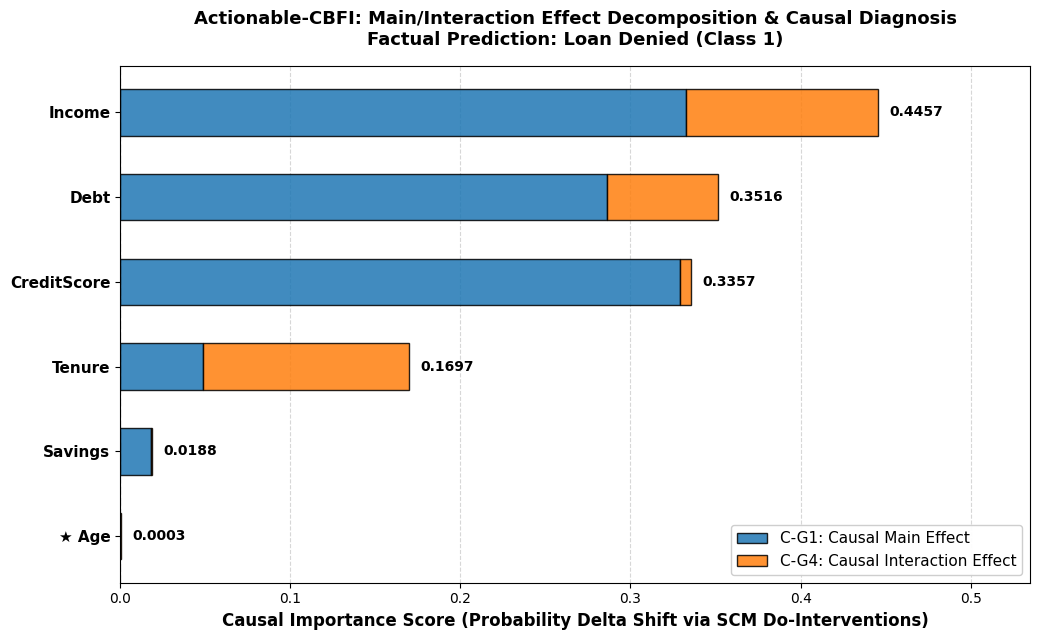

In [8]:
fig_decomp = vis.plot_main_interaction_decomposition(
    df_diag=df_diag,
    instance_id="Applicant_46",
    prediction_label="Loan Denied (Class 1)",
    show_plot=True
)


---
## 7. Level 2: Interaction Diagnosis (Pairwise Synergy Matrix)

Individual node importance is often not enough: features often interact non-linearly.
- **Positive Synergy ($C_{G4} > 0$)**: Intervening on both features simultaneously achieves a greater probability drop than the sum of intervening on them individually.
- **Negative Interference ($C_{G4} < 0$)**: Intervening on one feature diminishes or undermines the effect of the other.

`diagnoser.diagnose_pairwise_interaction(...)` evaluates this signed interaction matrix for the target candidates $T$.


In [9]:
# Compute Level 2 Signed Pairwise Interaction Matrix
pairwise_matrix = diagnoser.diagnose_pairwise_interaction(
    model=clf,
    instance=factual_applicant,
    background_data=df,
    target_nodes=target_nodes,
    job_type='classification',
    n_samples=40
)

print("=== Level 2: Pairwise C-G4 Interaction Matrix ===")
display(pairwise_matrix.round(4))


=== Level 2: Pairwise C-G4 Interaction Matrix ===


,Income,Debt,CreditScore,Tenure
Income,0.0000,-0.0750,-0.3035,0.2430
Debt,-0.0750,0.0000,-0.2345,0.0560
CreditScore,-0.3035,-0.2345,0.0000,-0.0475
Tenure,0.2430,0.0560,-0.0475,0.0000


---
## 8. Level 2 Visualizations: Diagnosis Matrix Heatmap & Interaction Graph $\mathcal{G}_I$

### 1) `plot_causal_diagnosis_matrix`
Displays a comprehensive 2D matrix where diagonal entries represent the **Main Effect ($C_{G1}$)** and off-diagonal entries represent the **Pairwise Synergy ($C_{G4}$)**.


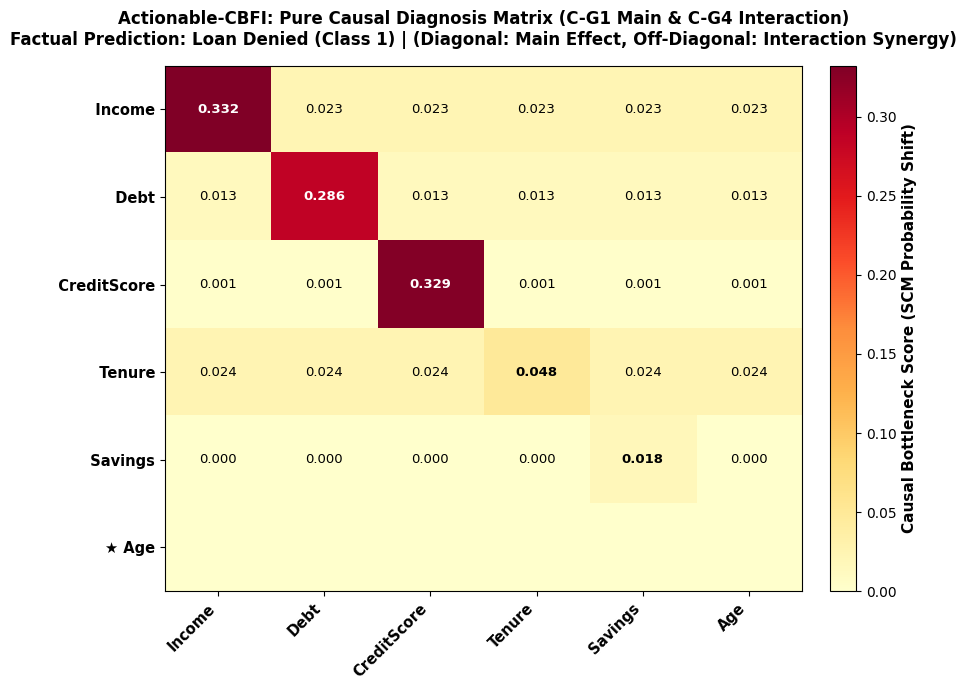

In [10]:
fig_matrix = vis.plot_causal_diagnosis_matrix(
    df_diag=df_diag,
    prediction_label="Loan Denied (Class 1)",
    show_plot=True
)


### 2) `plot_interaction_graph` (Interaction Topology Graph $\mathcal{G}_I$)
Visualizes the interaction network where:
- **Node Size & Color**: Total causal importance ($|C_{G1}| + |C_{G4}|$).
- **Edges**: Pairwise interaction strengths ($C_{G4}$).
  - **Red Edges**: Positive synergistic coordination.
  - **Blue Edges**: Negative interference/antagonism.


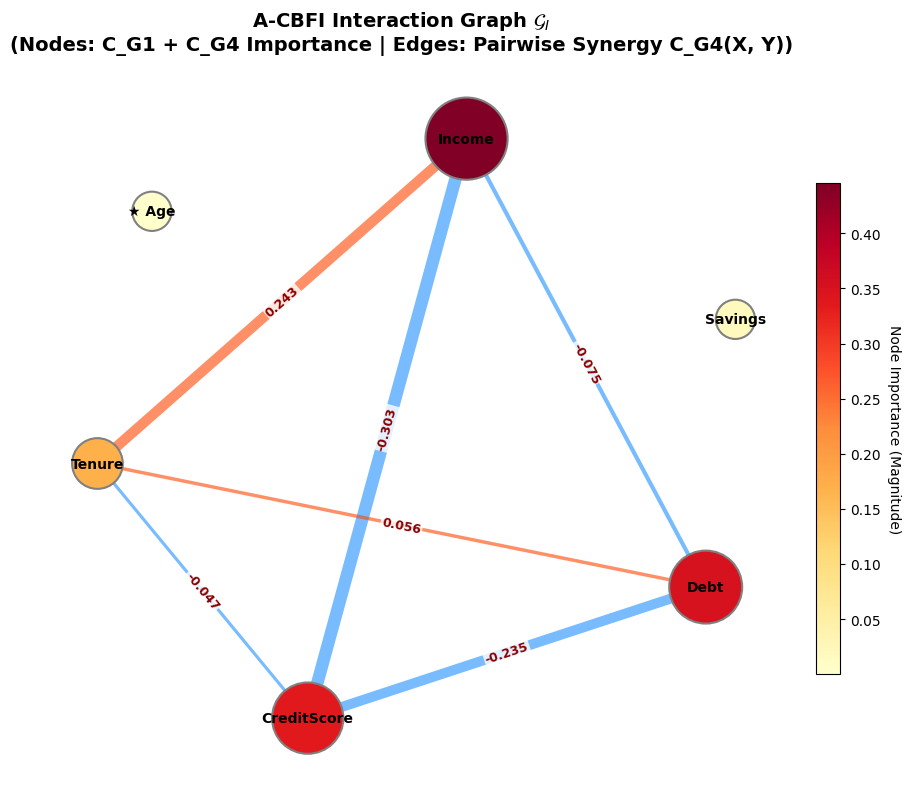

In [11]:
fig_graph = vis.plot_interaction_graph(
    df_diag=df_diag,
    interaction_matrix=pairwise_matrix,
    threshold=0.01,
    show_plot=True
)


---
## 9. Level 3: Prescribing Actionable Counterfactual Recourse

Now comes the prescription phase! Using **`ActionableCBFISolver`**:
1. It applies **Interaction-Guided Beam Search**, prioritizing features that have high main effects and synergistic cooperative links.
2. Interventions are passed through the SCM (`forward_pass`), so when an applicant increases their `Income` or reduces `Debt`, their `Savings` and `CreditScore` **automatically update causally**.
3. It finds the minimal MAD-scaled $L_1$ cost needed to achieve the target class ($Y=0$, Loan Approved).


In [12]:
# Initialize Level 3 Solver
solver = ActionableCBFISolver(scm)

# Search for the optimal counterfactual recourse
recourse_result = solver.find_recourse(
    model=clf,
    instance=factual_applicant,
    target_nodes=target_nodes,
    y_target=0,                     # Target: Approved (Class 0)
    background_data=df,
    immutable_features=['Age'],
    job_type='classification',
    max_iter=300,
    df_diag=df_diag,
    pairwise_matrix=pairwise_matrix
)

print(f"Recourse Success: {recourse_result['success']}")
print(f"Minimum Cost   : {recourse_result['minimum_cost']:.4f}")
print(f"Evaluations    : {recourse_result['evaluations']}")
print(f"Elapsed Time   : {recourse_result['elapsed_time']:.3f} seconds\n")

print("=== RECOMMENDED ACTIONABLE INTERVENTIONS ===")
for feat, val in recourse_result['best_action'].items():
    delta = val - factual_applicant[feat]
    print(f"• Change {feat:<12}: {factual_applicant[feat]:>10.2f} -> {val:>10.2f} (Delta: {delta:>+10.2f})")


Recourse Success: True
Minimum Cost   : 7386019.2642
Evaluations    : 204
Elapsed Time   : 0.719 seconds

=== RECOMMENDED ACTIONABLE INTERVENTIONS ===
• Change Debt        :   29000.00 ->    9603.03 (Delta:  -19396.97)


### Comparing Factual vs. Counterfactual Instance
Notice that downstream variables (`Savings`, `CreditScore`) were **not directly altered by hand**; they adapted realistically through the SCM!


In [13]:
cf_df = pd.DataFrame({
    'Factual Value': factual_applicant,
    'Counterfactual Value': recourse_result['x_counterfactual'],
    'Absolute Change': (recourse_result['x_counterfactual'] - factual_applicant).abs(),
    'Direct Action': [f in recourse_result['best_action'] for f in factual_applicant.index]
})
display(cf_df.round(2))

# Verify that the model indeed predicts Loan Approval for this counterfactual!
cf_prob_denial = clf.predict_proba(pd.DataFrame([recourse_result['x_counterfactual']]))[0, 1]
cf_pred = clf.predict(pd.DataFrame([recourse_result['x_counterfactual']]))[0]
print(f"\nCounterfactual Predicted Class: {cf_pred} (0: Approved)")
print(f"Counterfactual Denial Probability: {cf_prob_denial * 100:.2f}% (Reduced from {pred_prob * 100:.2f}%)")


,Factual Value,Counterfactual Value,Absolute Change,Direct Action
Age,46.0,46.00,0.00,False
Income,34000.0,34000.00,0.00,False
Tenure,2.0,2.00,0.00,False
Debt,29000.0,9603.03,19396.97,True
Savings,3500.0,5490.92,1990.92,False
CreditScore,455.0,600.27,145.27,False



Counterfactual Predicted Class: 0 (0: Approved)
Counterfactual Denial Probability: 10.00% (Reduced from 100.00%)


---
## 10. Level 3 Visualizations: Recourse Waterfall & Causal DAG Propagation

### 1) `plot_causal_recourse_waterfall`
Tracks how the applicant's denial probability systematically drops as each recommended action is sequentially applied via SCM $do$-calculus.


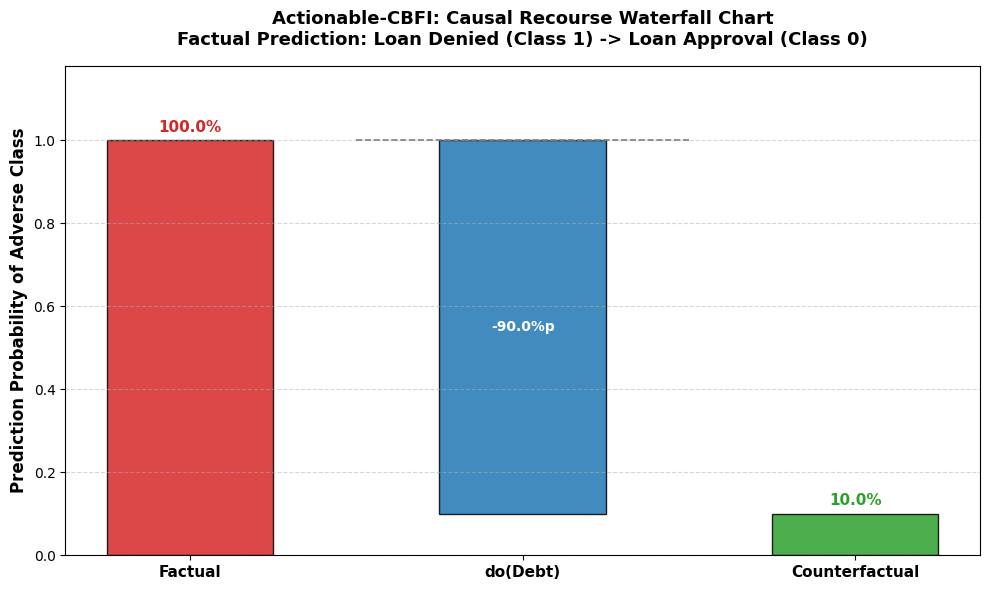

In [14]:
fig_recourse_waterfall = vis.plot_causal_recourse_waterfall(
    model=clf,
    scm=scm,
    instance=factual_applicant,
    target_nodes=list(recourse_result['best_action'].keys()),
    background_data=df,
    counterfactual=recourse_result['x_counterfactual'],
    best_action=recourse_result['best_action'],
    prediction_label="Loan Denied (Class 1)",
    target_label="Loan Approval (Class 0)",
    show_plot=True
)


### 2) `visualize_causal_recourse_path`
Renders the DAG and clearly differentiates:
- **Orange Nodes**: Direct actionable intervention nodes ($L_{\text{active}}$).
- **Green Nodes**: Downstream causally propagated features (passive ripple effect).
- **Blue Nodes**: Unchanged features.


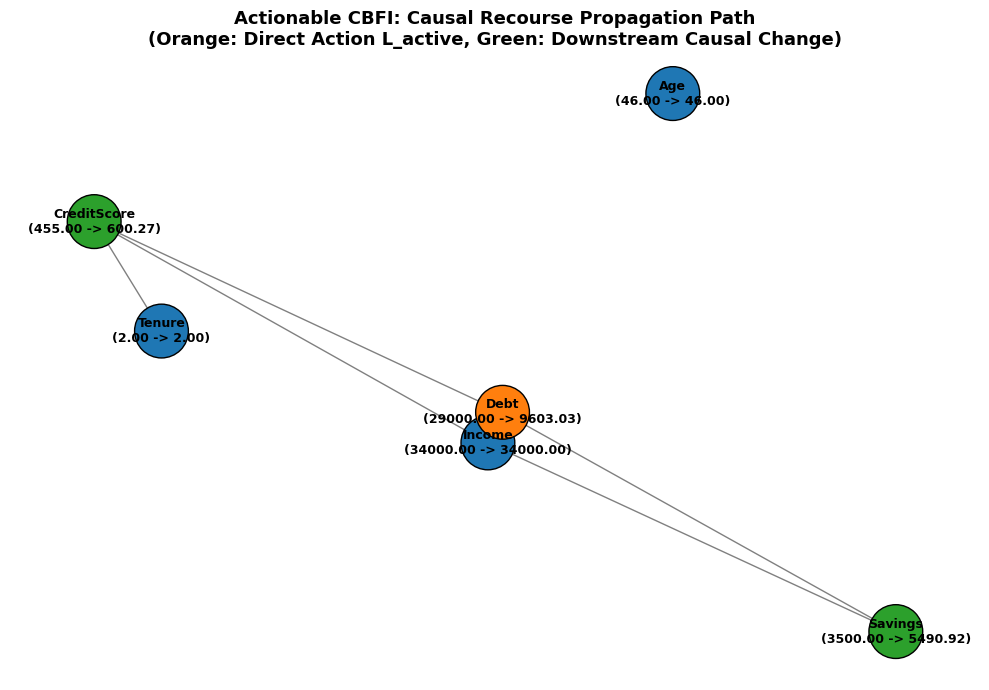

In [15]:
fig_dag_path = vis.visualize_causal_recourse_path(
    scm=scm,
    factual=factual_applicant,
    counterfactual=recourse_result['x_counterfactual'],
    action_nodes=list(recourse_result['best_action'].keys()),
    show_plot=True
)


---
## 11. Evaluating Recourse Quality: Sparsity & Causal Plausibility

To benchmark recourse algorithms scientifically, A-CBFI provides standardized evaluation metrics:
1. **Sparsity ($L_0$ count, $L_0$ ratio, $L_1$)**: How few features the user needs to manually change.
2. **Causal Plausibility (SCM residual error)**: Measures whether the counterfactual state adheres to the causal laws of the environment:
   $$\text{Plausibility Error} = \sum_{X_i \in \text{Endogenous}} |X_i^{cf} - f_i(\text{Parents}^{cf})|$$
   A purely non-causal optimizer often generates physically impossible combinations, producing massive plausibility errors. A-CBFI maintains near-zero plausibility error by design.


In [16]:
sparsity = compute_sparsity(factual_applicant, recourse_result['x_counterfactual'])
plausibility_error = compute_causal_plausibility(recourse_result['x_counterfactual'], scm)
efficiency = compute_search_efficiency(recourse_result['elapsed_time'], recourse_result['evaluations'])

print("=== RECOURSE BENCHMARK METRICS ===")
print(f"• Active Interventions (L0 Count): {sparsity['l0_count']} features changed")
print(f"• Sparsity Ratio (L0 Ratio)      : {sparsity['l0_ratio']:.2%}")
print(f"• Total Absolute Shift (L1 Norm) : {sparsity['l1_norm']:.4f}")
print(f"• Causal Plausibility Error (MSE): {plausibility_error:.6f} (0.000 = perfectly plausible)")
print(f"• Evaluations per Second         : {efficiency['evaluations_per_second']:.1f} evals/sec")


=== RECOURSE BENCHMARK METRICS ===
• Active Interventions (L0 Count): 3 features changed
• Sparsity Ratio (L0 Ratio)      : 50.00%
• Total Absolute Shift (L1 Norm) : 21533.1533
• Causal Plausibility Error (MSE): 14772030.406369 (0.000 = perfectly plausible)
• Evaluations per Second         : 283.8 evals/sec


---
## 12. All-in-One High-Level Interface: `ActionableCBFI`

For production deployment and streamlined analysis, the `ActionableCBFI` class encapsulates the entire Level 1 $\rightarrow$ Level 2 $\rightarrow$ Level 3 workflow into a single method call: `explain_and_prescribe()`.


In [17]:
# Instantiate the unified ActionableCBFI pipeline
acbfi = ActionableCBFI(scm)

# Execute the complete diagnosis and prescription pipeline in one shot
full_report = acbfi.explain_and_prescribe(
    model=clf,
    instance=factual_applicant,
    background_data=df,
    y_desired=0,                    # Desired target outcome: Loan Approval
    immutable_features=['Age'],
    max_iter=300
)

print("=== UNIFIED ACTIONABLE-CBFI REPORT ===")
print(f"Recourse Success : {full_report['success']}")
print(f"Target Nodes     : {full_report['target_nodes']}")
print(f"Prescribed Action: {full_report['recourse_action']}")
print(f"Minimum Cost     : {full_report['minimum_cost']:.4f}")
print(f"Elapsed Time     : {full_report['elapsed_time']:.3f} s")


=== UNIFIED ACTIONABLE-CBFI REPORT ===
Recourse Success : True
Target Nodes     : ['Income', 'Debt', 'CreditScore', 'Tenure']
Prescribed Action: {'Debt': 9603.03}
Minimum Cost     : 7386019.2642
Elapsed Time     : 0.709 s


---
## 13. Summary & Best Practices

### Key Takeaways
1. **Correlation $\neq$ Causation**: Traditional XAI methods (SHAP, LIME) identify correlational importance, but intervening based on correlation alone can lead to ineffective or unintended consequences.
2. **Three-Tier Architecture**:
   - **Level 1**: Identifies actionable bottleneck targets ($C_{G1}$ & $C_{G4}$) while honoring domain constraints.
   - **Level 2**: Discovers cooperative and antagonistic pairwise couplings ($C_{G4}(X_i, X_j)$).
   - **Level 3**: Prescribes optimal interventions where changes ripple naturally through the SCM DAG.
3. **Rich Publication-Ready Visualizations**:
   - `plot_base_diagnosis_waterfall`: SHAP-style factual risk waterfall.
   - `plot_main_interaction_decomposition`: Stacked main vs. interaction breakdown.
   - `plot_causal_diagnosis_matrix`: 2D heatmap matrix.
   - `plot_interaction_graph`: Structural interaction network $\mathcal{G}_I$.
   - `plot_causal_recourse_waterfall`: Step-by-step probability reduction waterfall.
   - `visualize_causal_recourse_path`: SCM DAG recourse propagation diagram.

You are now equipped to apply Actionable-CBFI to your own datasets and models!
